# Ames Housing Price Prediction

We used the Ames training data to predict `SalePrice`. This notebook follows our model changes, local checks, and Kaggle submissions. To run it, put `train.csv`, `test.csv`, and `sample_soln.csv` in the same folder. The last prediction cell creates `ames_submission_v11.csv`.

V11 has our lowest recorded Kaggle RMSE: **33,765.45286 public** and **23,767.77978 private**.

| Version | Public RMSE | Private RMSE | Note |
|---|---:|---:|---|
| V1 | — | — | Earlier single reported score: 47,747.14610; column not recorded |
| V2 | 48,933.65229 | 27,830.63078 | Submitted |
| V3 | 93,548.61488 | 27,690.63477 | Submitted |
| V4 | 46,902.58043 | 28,962.85640 | Submitted |
| V5 | 46,522.63795 | 29,054.06949 | Submitted |
| V6 | — | — | Not submitted |
| V7 | 38,539.35879 | 25,786.57620 | Submitted |
| V8 | 37,981.98779 | 24,559.78418 | Submitted |
| V9 | 36,923.54265 | 24,300.38740 | Submitted |
| V10 | 36,051.69991 | 24,149.83432 | Submitted |
| V11 | **33,765.45286** | **23,767.77978** | Submitted |

The scores come from our Kaggle results. We have both columns for V2–V5 and V7–V11. The earlier V1 score did not include a column label, and V6 was not uploaded. We did not use `solns.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from IPython.display import display

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)

Matplotlib is building the font cache; this may take a moment.


pandas: 3.0.5
NumPy: 2.5.4
scikit-learn: 1.9.1


## 1. Inspect the data

Each row is one house. `SalePrice` is the target and `Id` is excluded from the predictors. Empty fields are treated as missing; explicit category labels such as `None` are preserved. We check dimensions, duplicate IDs, and missing targets.

In [2]:
data = pd.read_csv('train.csv', keep_default_na=False, na_values=[''])
print('Rows and columns:', data.shape)
print('Duplicate Id values:', data['Id'].duplicated().sum())
print('Missing SalePrice values:', data['SalePrice'].isna().sum())
assert data['Id'].is_unique
assert data['SalePrice'].notna().all()
display(data.head())
display(data.dtypes.value_counts().rename('Number of columns').to_frame())

Rows and columns: (1200, 81)
Duplicate Id values: 0
Missing SalePrice values: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Number of columns
str,43
int64,35
float64,3


## 2. Split and explore

We use 960 houses for training and 240 for validation (`random_state=42`). Price relationships are explored on the training portion. Preprocessing is fitted on training rows only.

This validation set is used for model selection. Its score is not an independent test or Kaggle score.

In [3]:
X = data.drop(columns=['Id', 'SalePrice'])
y = data['SalePrice']
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Training houses:', len(X_train))
print('Validation houses:', len(X_valid))
assert set(X_train.index).isdisjoint(X_valid.index)

eda = X_train.copy()
eda['SalePrice'] = y_train
missing = X_train.isna().sum().sort_values(ascending=False)
missing_table = pd.DataFrame({
    'Missing count': missing[missing > 0],
    'Missing percent': 100 * missing[missing > 0] / len(X_train)
})
display(missing_table)
display(y_train.describe().to_frame('Training SalePrice'))

Training houses: 960
Validation houses: 240


,Missing count,Missing percent
PoolQC,956,99.58
MiscFeature,920,95.83
Alley,904,94.17
Fence,782,81.46
FireplaceQu,443,46.15
LotFrontage,171,17.81
GarageType,52,5.42
GarageYrBlt,52,5.42
GarageQual,52,5.42
GarageCond,52,5.42


,Training SalePrice
count,960.00
mean,"183,602.91"
std,"82,061.96"
min,"34,900.00"
25%,"132,000.00"
50%,"164,800.00"
75%,"219,500.00"
max,"755,000.00"


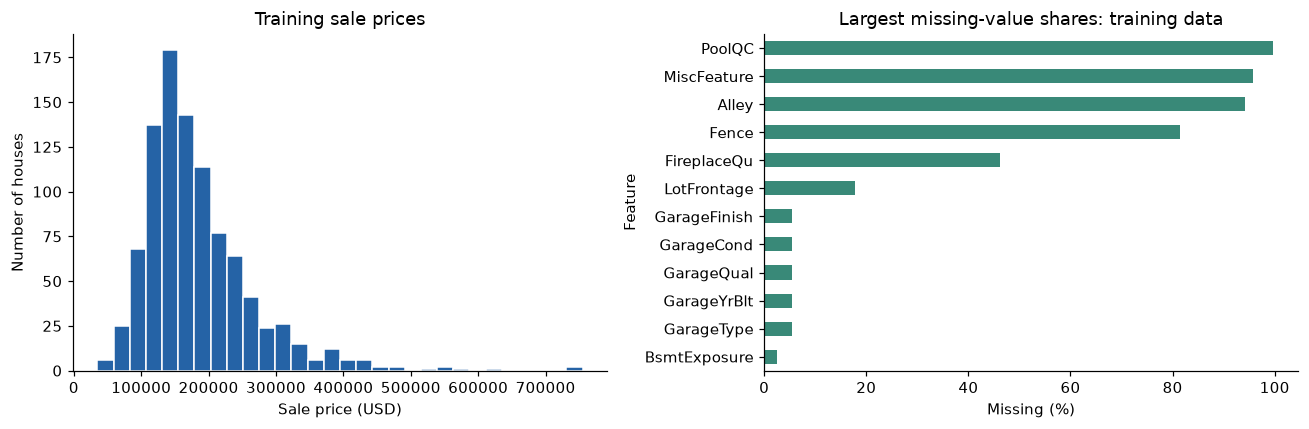

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=30, color='#2563a6', edgecolor='white')
axes[0].set(title='Training sale prices', xlabel='Sale price (USD)', ylabel='Number of houses')
missing_table.head(12)['Missing percent'].sort_values().plot.barh(ax=axes[1], color='#398978')
axes[1].set(title='Largest missing-value shares: training data', xlabel='Missing (%)', ylabel='Feature')
fig.tight_layout()
plt.show()

Training prices are right-skewed: the mean is USD 183,603 and the median is USD 164,800. Large errors can strongly affect RMSE.

Several missing fields indicate absent facilities, so they need to be interpreted before imputation. We first examine quality, area, age, garage capacity, and neighborhood.

,Correlation with SalePrice
OverallQual,0.79
GrLivArea,0.76
TotalBsmtSF,0.66
GarageCars,0.65
FullBath,0.57
YearBuilt,0.52
YearRemodAdd,0.50
Fireplaces,0.45
LotArea,0.27


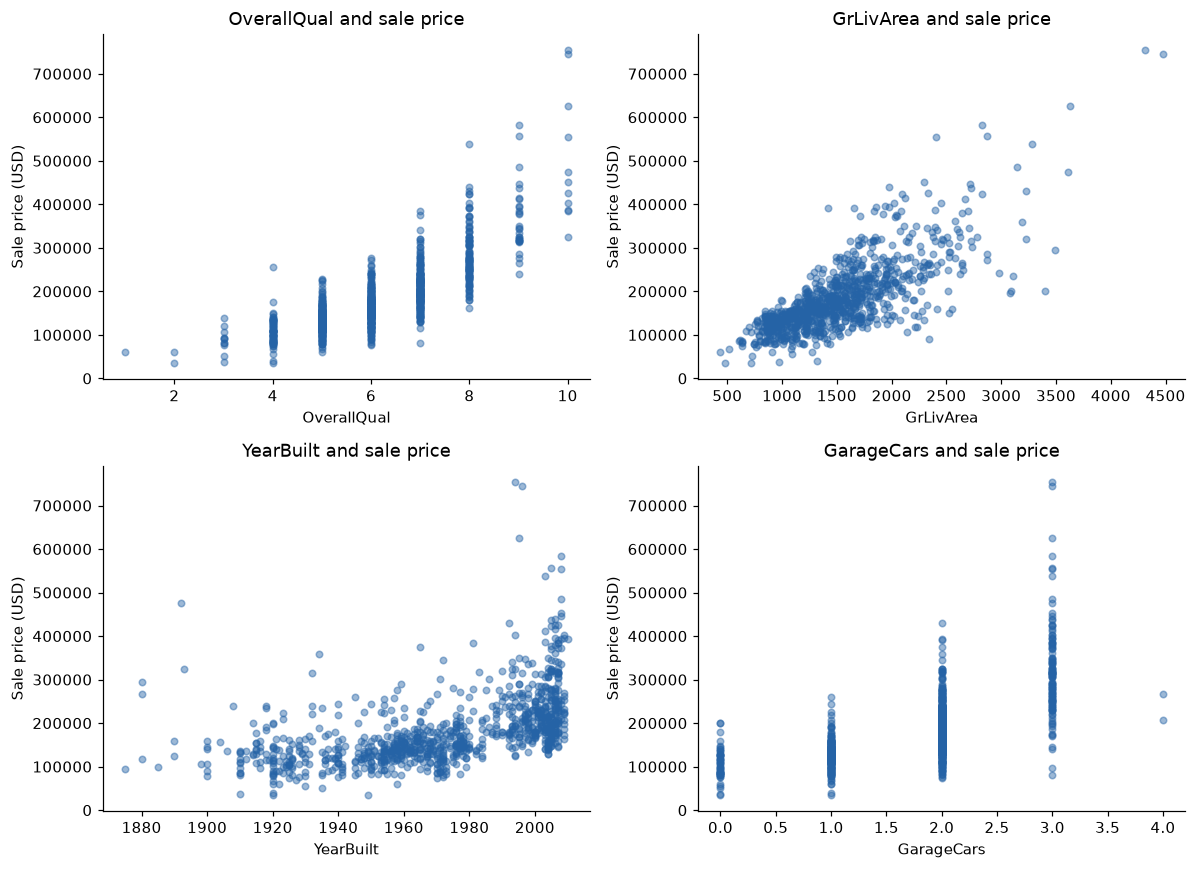

,count,mean,median
Neighborhood,,,
NridgHt,58,"315,941.72","311,906.50"
NoRidge,30,"337,498.00","290,000.00"
StoneBr,20,"305,692.90","280,500.00"
Timber,25,"243,253.08","228,000.00"
ClearCr,19,"222,757.89","225,000.00"
Somerst,53,"219,891.66","222,000.00"
Veenker,9,"238,388.89","218,000.00"
CollgCr,98,"199,931.93","200,320.50"
Crawfor,31,"206,749.16","200,100.00"


In [5]:
initial_features = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
                    'YearBuilt', 'YearRemodAdd', 'FullBath', 'Fireplaces', 'LotArea']
display(eda[initial_features + ['SalePrice']].corr()['SalePrice']
        .drop('SalePrice').sort_values(ascending=False)
        .rename('Correlation with SalePrice').to_frame())

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.ravel(), ['OverallQual', 'GrLivArea', 'YearBuilt', 'GarageCars']):
    ax.scatter(eda[feature], eda['SalePrice'], alpha=0.45, s=18, color='#2563a6')
    ax.set(xlabel=feature, ylabel='Sale price (USD)', title=feature + ' and sale price')
fig.tight_layout()
plt.show()

display(eda.groupby('Neighborhood')['SalePrice'].agg(['count', 'mean', 'median'])
        .sort_values('median', ascending=False))

Overall quality and living area have training correlations of about 0.79 and 0.76 with price. Neighborhood prices also vary, although some neighborhoods have few observations.

**Preprocessing choices**

- Retain all houses, including unusual observations.
- Fill remaining numeric missing values with training means and categorical missing values with training modes.
- Label missing basement quality as `NoBasement` when basement area is zero; use `NoGarage` when garage area is zero.
- One-hot encode ordinary categories. Encode quality as `Po < Fa < TA < Gd < Ex`, with `NoBasement` first for basement quality. Equal spacing between quality codes is an approximation.

In [6]:
def prepare_features(frame):
    # These rules use each house's own features, not prices or dataset averages.
    result = frame.copy()
    no_basement = result['BsmtQual'].isna() & (result['TotalBsmtSF'] == 0)
    no_garage = result['GarageType'].isna() & (result['GarageArea'] == 0)
    result.loc[no_basement, 'BsmtQual'] = 'NoBasement'
    result.loc[no_garage, 'GarageType'] = 'NoGarage'

    result['HouseAge'] = result['YrSold'] - result['YearBuilt']
    result['YearsSinceRemodel'] = result['YrSold'] - result['YearRemodAdd']
    # A fixed change of units keeps polynomial terms at a manageable scale.
    result['LivingArea1000'] = result['GrLivArea'] / 1000
    result['LivingArea1000Squared'] = result['LivingArea1000'] ** 2
    return result

X_train_prepared = prepare_features(X_train)
X_valid_prepared = prepare_features(X_valid)
print('Training houses labeled NoBasement:',
      (X_train_prepared['BsmtQual'] == 'NoBasement').sum())
print('Training houses labeled NoGarage:',
      (X_train_prepared['GarageType'] == 'NoGarage').sum())
display(X_train_prepared[['YearBuilt', 'YrSold', 'HouseAge',
                          'YearsSinceRemodel', 'LivingArea1000']].head())

Training houses labeled NoBasement: 24
Training houses labeled NoGarage: 52


,YearBuilt,YrSold,HouseAge,YearsSinceRemodel,LivingArea1000
331,1958,2007,49,15,1.06
409,2007,2008,1,0,2.08
76,1956,2008,52,52,0.95
868,1948,2006,58,56,2.32
138,1999,2008,9,8,1.85


## 3. Establish baselines

The first baseline predicts the training mean for every house. The first regression uses only `OverallQual`. We record training and validation RMSE using `np.sqrt(mean_squared_error(actual, predicted))`.

In [7]:
results = []
fitted_models = {}
validation_predictions = {}

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

def evaluate_model(name, model):
    model.fit(X_train_prepared, y_train)
    train_predictions = model.predict(X_train_prepared)
    valid_predictions = model.predict(X_valid_prepared)
    results.append({'Model': name,
                    'Train RMSE': rmse(y_train, train_predictions),
                    'Validation RMSE': rmse(y_valid, valid_predictions)})
    fitted_models[name] = model
    validation_predictions[name] = valid_predictions
    print(f'{name}: validation RMSE = USD {rmse(y_valid, valid_predictions):,.2f}')

mean_train_predictions = np.ones(len(y_train)) * y_train.mean()
mean_valid_predictions = np.ones(len(y_valid)) * y_train.mean()
results.append({'Model': '0. Training-mean baseline',
                'Train RMSE': rmse(y_train, mean_train_predictions),
                'Validation RMSE': rmse(y_valid, mean_valid_predictions)})
validation_predictions['0. Training-mean baseline'] = mean_valid_predictions

single_transformer = make_column_transformer(
    (SimpleImputer(strategy='mean'), ['OverallQual']), remainder='drop'
)
single_model = Pipeline([('prepare', single_transformer), ('model', LinearRegression())])
evaluate_model('1. OverallQual only', single_model)
display(pd.DataFrame(results))

1. OverallQual only: validation RMSE = USD 49,041.38


,Model,Train RMSE,Validation RMSE
0,0. Training-mean baseline,"82,019.21","77,138.93"
1,1. OverallQual only,"50,014.76","49,041.38"


## 4. Add numeric and categorical features

We first use nine numeric features, then add five categorical features and four quality features. Missing-value imputation runs before encoding inside each pipeline. Each candidate gets a new pipeline.

One-hot encoding drops one reference category and ignores unseen categories. Quality categories use their stated order.

In [8]:
numeric_features = initial_features.copy()
category_features = ['Neighborhood', 'MSZoning', 'BldgType', 'HouseStyle', 'GarageType']
quality_features = ['ExterQual', 'KitchenQual', 'HeatingQC', 'BsmtQual']
quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
quality_categories = [quality_order, quality_order, quality_order,
                      ['NoBasement'] + quality_order]

numeric_transformer = make_column_transformer(
    (SimpleImputer(strategy='mean'), numeric_features), remainder='drop'
)
numeric_model = Pipeline([('prepare', numeric_transformer), ('model', LinearRegression())])
evaluate_model('2. Multiple numeric features', numeric_model)

def make_housing_model(number_columns, polynomial=False):
    category_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore'))
    ])
    quality_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OrdinalEncoder(categories=quality_categories))
    ])
    transformations = [
        (SimpleImputer(strategy='mean'), number_columns),
        (category_pipe, category_features),
        (quality_pipe, quality_features)
    ]
    if polynomial:
        polynomial_pipe = Pipeline([
            ('impute', SimpleImputer(strategy='mean')),
            ('polynomial', PolynomialFeatures(degree=2, include_bias=False))
        ])
        transformations.append((polynomial_pipe, ['LivingArea1000', 'OverallQual']))
    transformer = make_column_transformer(*transformations, remainder='drop')
    return Pipeline([('prepare', transformer), ('model', LinearRegression())])

mixed_model = make_housing_model(numeric_features)
evaluate_model('3. Numeric + categorical features', mixed_model)

2. Multiple numeric features: validation RMSE = USD 42,890.02
3. Numeric + categorical features: validation RMSE = USD 37,153.09


## 5. Try feature engineering

We test three changes:

1. Replace construction and remodeling years with house age and years since remodeling.
2. Add a squared living-area term.
3. Add degree-2 terms for living area and quality, including their interaction.

Polynomial terms are fitted on training inputs. Original area and quality columns are removed from the separate numeric branch when the polynomial branch includes them.

In [9]:
age_features = [col for col in numeric_features if col not in ['YearBuilt', 'YearRemodAdd']]
age_features += ['HouseAge', 'YearsSinceRemodel']

age_model = make_housing_model(age_features)
evaluate_model('4. Age features', age_model)

square_features = age_features + ['LivingArea1000Squared']
square_model = make_housing_model(square_features)
evaluate_model('5. Age + living-area square', square_model)

polynomial_numeric_features = [col for col in age_features
                               if col not in ['GrLivArea', 'OverallQual']]
polynomial_model = make_housing_model(polynomial_numeric_features, polynomial=True)
evaluate_model('6. Age + area/quality quadratic', polynomial_model)

4. Age features: validation RMSE = USD 37,231.22
5. Age + living-area square: validation RMSE = USD 48,481.70
6. Age + area/quality quadratic: validation RMSE = USD 46,320.49


## 6. Compare models and inspect errors

For this first comparison, we select the lowest validation RMSE. Training RMSE helps identify overfitting. All attempted models remain in the table.

,Model,Train RMSE,Validation RMSE,Validation minus train,Improvement vs baseline (%)
0,3. Numeric + categorical features,"29,124.68","37,153.09","8,028.41",51.84
1,4. Age features,"29,206.81","37,231.22","8,024.41",51.73
2,2. Multiple numeric features,"33,391.97","42,890.02","9,498.05",44.40
3,6. Age + area/quality quadratic,"23,827.19","46,320.49","22,493.30",39.95
4,5. Age + living-area square,"25,485.58","48,481.70","22,996.12",37.15
5,1. OverallQual only,"50,014.76","49,041.38",-973.38,36.42
6,0. Training-mean baseline,"82,019.21","77,138.93","-4,880.28",0.00


Selected candidate: 3. Numeric + categorical features
Validation RMSE: USD 37,153.09
Improvement over the mean baseline: 51.8%


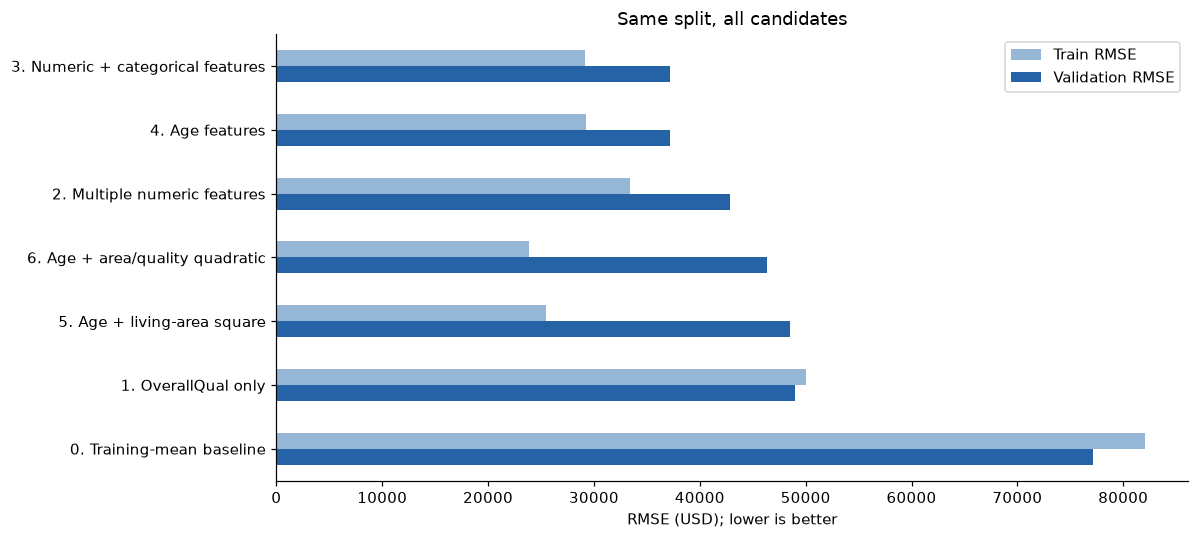

In [10]:
comparison = pd.DataFrame(results)
baseline_rmse = comparison.loc[0, 'Validation RMSE']
comparison['Validation minus train'] = comparison['Validation RMSE'] - comparison['Train RMSE']
comparison['Improvement vs baseline (%)'] = (
    100 * (baseline_rmse - comparison['Validation RMSE']) / baseline_rmse
)
comparison = comparison.sort_values('Validation RMSE').reset_index(drop=True)
display(comparison)

best_name = comparison.loc[0, 'Model']
best_validation_rmse = comparison.loc[0, 'Validation RMSE']
best_model = fitted_models.get(best_name)
best_predictions = validation_predictions[best_name]
print('Selected candidate:', best_name)
print(f'Validation RMSE: USD {best_validation_rmse:,.2f}')
print(f'Improvement over the mean baseline: '
      f'{100 * (baseline_rmse - best_validation_rmse) / baseline_rmse:.1f}%')

plot_table = comparison.set_index('Model')[['Train RMSE', 'Validation RMSE']]
ax = plot_table.plot.barh(figsize=(11, 5), color=['#95b6d4', '#2563a6'])
ax.invert_yaxis()
ax.set(xlabel='RMSE (USD); lower is better', ylabel='', title='Same split, all candidates')
plt.tight_layout()
plt.show()

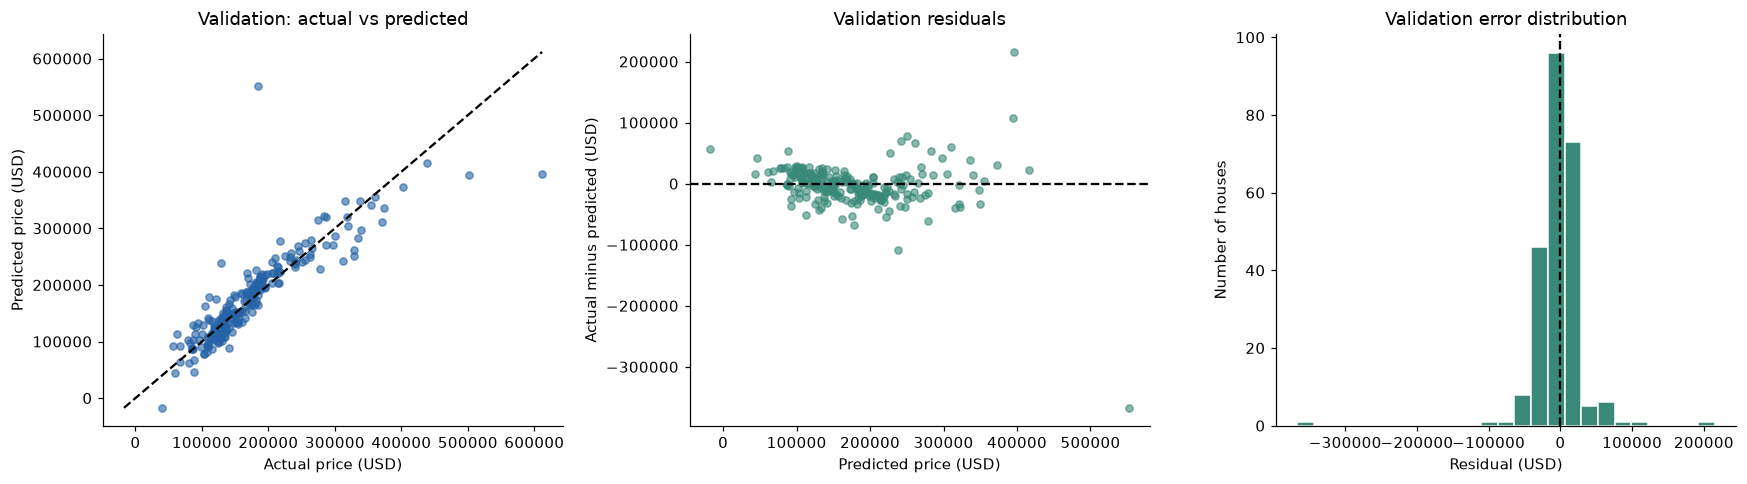

Mean validation residual: USD -2,339.27
Nonpositive validation predictions: 1


,Id,Actual SalePrice,Predicted SalePrice,Residual,Absolute error
523,524,184750,"551,883.93","-367,133.93","367,133.93"
898,899,611657,"396,017.44","215,639.56","215,639.56"
666,667,129000,"238,077.51","-109,077.51","109,077.51"
178,179,501837,"394,921.18","106,915.82","106,915.82"
885,886,328900,"250,358.95","78,541.05","78,541.05"
218,219,311500,"242,230.11","69,269.89","69,269.89"
728,729,110000,"178,081.61","-68,081.61","68,081.61"
1065,1066,328000,"261,551.62","66,448.38","66,448.38"
113,114,217000,"278,346.80","-61,346.80","61,346.80"
644,645,370878,"310,519.35","60,358.65","60,358.65"


In [11]:
diagnostics = pd.DataFrame({
    'Id': data.loc[y_valid.index, 'Id'],
    'Actual SalePrice': y_valid,
    'Predicted SalePrice': best_predictions
})
diagnostics['Residual'] = diagnostics['Actual SalePrice'] - diagnostics['Predicted SalePrice']
diagnostics['Absolute error'] = diagnostics['Residual'].abs()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(diagnostics['Actual SalePrice'], diagnostics['Predicted SalePrice'],
                alpha=0.6, s=22, color='#2563a6')
limits = [min(diagnostics['Actual SalePrice'].min(), diagnostics['Predicted SalePrice'].min()),
          max(diagnostics['Actual SalePrice'].max(), diagnostics['Predicted SalePrice'].max())]
axes[0].plot(limits, limits, '--', color='black')
axes[0].set(xlabel='Actual price (USD)', ylabel='Predicted price (USD)', title='Validation: actual vs predicted')
axes[1].scatter(diagnostics['Predicted SalePrice'], diagnostics['Residual'],
                alpha=0.6, s=22, color='#398978')
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Predicted price (USD)', ylabel='Actual minus predicted (USD)', title='Validation residuals')
axes[2].hist(diagnostics['Residual'], bins=25, color='#398978', edgecolor='white')
axes[2].axvline(0, color='black', linestyle='--')
axes[2].set(xlabel='Residual (USD)', ylabel='Number of houses', title='Validation error distribution')
fig.tight_layout()
plt.show()

print(f'Mean validation residual: USD {diagnostics["Residual"].mean():,.2f}')
print('Nonpositive validation predictions:', (best_predictions <= 0).sum())
display(diagnostics.sort_values('Absolute error', ascending=False).head(10))

Positive residuals mean underprediction; negative residuals mean overprediction. We also compare errors across actual-price groups. These groups are used only for diagnostics, and no houses are removed after inspecting their errors.

In [12]:
diagnostics['Actual-price group'] = pd.cut(
    diagnostics['Actual SalePrice'],
    bins=[0, 150000, 250000, np.inf],
    labels=['Below USD 150k', 'USD 150k–USD 250k', 'Above USD 250k'],
    right=False
)
group_results = []
for group in ['Below USD 150k', 'USD 150k–USD 250k', 'Above USD 250k']:
    subset = diagnostics[diagnostics['Actual-price group'] == group]
    group_results.append({
        'Actual-price group': group,
        'Houses': len(subset),
        'RMSE': rmse(subset['Actual SalePrice'], subset['Predicted SalePrice']),
        'Mean residual': subset['Residual'].mean()
    })
display(pd.DataFrame(group_results))

if best_model is not None:
    print('Selected model input columns after preprocessing:',
          best_model.named_steps['prepare'].transform(X_train_prepared).shape[1])
assert np.isfinite(best_predictions).all()
assert len(best_predictions) == len(y_valid)

,Actual-price group,Houses,RMSE,Mean residual
0,Below USD 150k,110,"24,465.61","-1,469.59"
1,USD 150k–USD 250k,99,"41,472.55","-11,854.87"
2,Above USD 250k,31,"55,406.11","24,963.32"


Selected model input columns after preprocessing: 58


In [13]:
# Keep unusual cases visible instead of deleting them after evaluation.
review_columns = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'Neighborhood', 'SaleCondition']
review = diagnostics.join(X_valid[review_columns])
print('Largest validation errors, with house characteristics:')
display(review.sort_values('Absolute error', ascending=False).head(5))
print('Nonpositive predictions requiring attention before the submission stage:')
display(review[review['Predicted SalePrice'] <= 0])
squared_errors = diagnostics['Residual'] ** 2
print(f'Largest error as a share of total validation squared error: '
      f'{100 * squared_errors.max() / squared_errors.sum():.1f}%')
print('Training living-area range:', X_train['GrLivArea'].min(), 'to', X_train['GrLivArea'].max())
print('Validation living-area range:', X_valid['GrLivArea'].min(), 'to', X_valid['GrLivArea'].max())

Largest validation errors, with house characteristics:


,Id,Actual SalePrice,Predicted SalePrice,Residual,Absolute error,Actual-price group,OverallQual,GrLivArea,TotalBsmtSF,Neighborhood,SaleCondition
523,524,184750,"551,883.93","-367,133.93","367,133.93",USD 150k–USD 250k,10,4676,3138,Edwards,Partial
898,899,611657,"396,017.44","215,639.56","215,639.56",Above USD 250k,9,2364,2330,NridgHt,Partial
666,667,129000,"238,077.51","-109,077.51","109,077.51",Below USD 150k,6,2380,1021,NAmes,Abnorml
178,179,501837,"394,921.18","106,915.82","106,915.82",Above USD 250k,9,2234,2216,StoneBr,Partial
885,886,328900,"250,358.95","78,541.05","78,541.05",Above USD 250k,9,1709,1698,Somerst,Abnorml


Nonpositive predictions requiring attention before the submission stage:


,Id,Actual SalePrice,Predicted SalePrice,Residual,Absolute error,Actual-price group,OverallQual,GrLivArea,TotalBsmtSF,Neighborhood,SaleCondition
533,534,39300,"-17,195.18","56,495.18","56,495.18",Below USD 150k,1,334,0,BrkSide,Normal


Largest error as a share of total validation squared error: 40.7%
Training living-area range: 438 to 4476
Validation living-area range: 334 to 4676


### Initial findings

Numeric plus categorical features perform best in this initial holdout comparison. The age model is close. Polynomial terms lower training error but worsen validation performance, so they are not retained.

Id 524 is the largest validation error and has an area above the training range. Id 534 has an area below the training range and receives a negative prediction. Both remain in scoring. The following section evaluates nonnegative predictions and checks stability across folds.

## 7. Check stability with cross-validation

We compare original-year and age models, with and without four extra features: first-floor area, second-floor area, garage area, and overall condition.

Three shuffled 5-fold rounds give 15 paired scores per model. Preprocessing is learned separately in each fold. We compare raw predictions and `max(prediction, 0)`.

Cross-validation uses all 1,200 labeled houses, including the earlier holdout. These are model-selection results, not independent test scores.

In [14]:
from sklearn.base import clone
from sklearn.model_selection import KFold
import warnings

candidate_models = {
    'Original years': make_housing_model(numeric_features),
    'House ages': make_housing_model(age_features),
    'Years + added area/condition': make_housing_model(
        numeric_features + ['1stFlrSF', '2ndFlrSF', 'GarageArea', 'OverallCond']),
    'Ages + added area/condition': make_housing_model(
        age_features + ['1stFlrSF', '2ndFlrSF', 'GarageArea', 'OverallCond']),
}
cv_rows = []
for repeat, seed in enumerate([42, 2026, 123], start=1):
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), start=1):
        X_fit = prepare_features(X.iloc[fit_idx])
        X_score = prepare_features(X.iloc[score_idx])
        y_fit, y_score = y.iloc[fit_idx], y.iloc[score_idx]
        for name, prototype in candidate_models.items():
            model = clone(prototype)
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Found unknown categories')
                model.fit(X_fit, y_fit)
                raw = model.predict(X_score)
            for rule, preds in [('raw', raw), ('nonnegative', np.maximum(raw, 0))]:
                cv_rows.append({
                    'Model': name, 'Prediction rule': rule,
                    'Repeat': repeat, 'Fold': fold,
                    'RMSE': rmse(y_score, preds),
                    'MSE': mean_squared_error(y_score, preds),
                    'Negative predictions': int((preds < 0).sum())
                })
cv_details = pd.DataFrame(cv_rows)
cv_summary = cv_details.groupby(['Model', 'Prediction rule']).agg(
    Mean_RMSE=('RMSE', 'mean'),
    Fold_SD=('RMSE', 'std'),
    Pooled_RMSE=('MSE', lambda values: np.sqrt(values.mean())),
    Negative_predictions=('Negative predictions', 'sum')
).reset_index().sort_values('Mean_RMSE')
display(cv_summary)


,Model,Prediction rule,Mean_RMSE,Fold_SD,Pooled_RMSE,Negative_predictions
0,Ages + added area/condition,nonnegative,"31,693.33","5,157.21","32,082.56",0
6,Years + added area/condition,nonnegative,"31,696.39","5,171.09","32,087.67",0
1,Ages + added area/condition,raw,"31,728.06","5,152.55","32,116.17",3
7,Years + added area/condition,raw,"31,731.75","5,166.21","32,121.86",3
2,House ages,nonnegative,"32,090.60","4,999.08","32,451.99",0
3,House ages,raw,"32,106.54","4,999.81","32,467.85",3
4,Original years,nonnegative,"32,124.07","4,991.49","32,483.99",0
5,Original years,raw,"32,144.60","4,988.29","32,503.84",3


In [15]:
# Use the *same original holdout* as an additional diagnostic, not a new test set.
holdout_rows = []
for name, prototype in candidate_models.items():
    model = clone(prototype).fit(X_train_prepared, y_train)
    raw = model.predict(X_valid_prepared)
    for rule, preds in [('raw', raw), ('nonnegative', np.maximum(raw, 0))]:
        holdout_rows.append({'Model': name, 'Prediction rule': rule,
                             'Holdout RMSE': rmse(y_valid, preds),
                             'Negative predictions': int((preds < 0).sum())})
holdout_summary = pd.DataFrame(holdout_rows)
display(holdout_summary.sort_values('Holdout RMSE'))

original_cv = cv_summary[(cv_summary['Model'] == 'Original years') &
                         (cv_summary['Prediction rule'] == 'nonnegative')].iloc[0]
age_cv = cv_summary[(cv_summary['Model'] == 'House ages') &
                    (cv_summary['Prediction rule'] == 'nonnegative')].iloc[0]
print('Age minus original mean fold RMSE: '
      f"USD {age_cv['Mean_RMSE'] - original_cv['Mean_RMSE']:,.2f}")


,Model,Prediction rule,Holdout RMSE,Negative predictions
1,Original years,nonnegative,"37,060.61",0
0,Original years,raw,"37,153.09",1
3,House ages,nonnegative,"37,155.97",0
2,House ages,raw,"37,231.22",1
5,Years + added area/condition,nonnegative,"37,351.87",0
7,Ages + added area/condition,nonnegative,"37,383.59",0
4,Years + added area/condition,raw,"37,499.42",1
6,Ages + added area/condition,raw,"37,528.34",1


Age minus original mean fold RMSE: USD -33.47


### V1 decision

The original-year and age versions were close in cross-validation. Adding more area features helped some folds but made the fixed holdout slightly worse. We kept the simpler original-year model and changed negative predictions to zero. That rule was included in local scoring before submission.

## 8. Refit the V1 specification

Refit the original-year pipeline on all labeled houses. The following cell regenerates its predictions as `ames_submission_sample_ids.csv`. The exact previously submitted V1 file remains separately preserved as `ames_submission_v1.csv`.

The user reported a Kaggle score for the supplied file on 2026-10-31, indicating acceptance of `Id,SalePrice` with sample IDs 0–259. Keep this format for V2.

In [16]:
test = pd.read_csv('test.csv', keep_default_na=False, na_values=[''])
sample = pd.read_csv('sample_soln.csv')
assert len(test) == len(sample) == 260
assert test['Id'].is_unique and sample['Id'].is_unique
assert (sample['Id'].to_numpy() == np.arange(len(sample))).all()
assert (test['Id'].to_numpy() == np.arange(1201, 1461)).all()
assert all(col in test.columns for col in X.columns)

final_model = make_housing_model(numeric_features)
final_model.fit(prepare_features(X), y)
test_predictions = np.maximum(final_model.predict(prepare_features(test.drop(columns='Id'))), 0)
submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': test_predictions})
assert submission.columns.tolist() == ['Id', 'SalePrice']
assert submission['Id'].equals(sample['Id'])
assert submission['SalePrice'].notna().all()
assert np.isfinite(submission['SalePrice']).all()
assert (submission['SalePrice'] >= 0).all()
submission.to_csv('ames_submission_sample_ids.csv', index=False)
print('Saved ames_submission_sample_ids.csv', submission.shape)
print('Prediction range:', submission['SalePrice'].min(), 'to', submission['SalePrice'].max())
display(submission.head())


Saved ames_submission_sample_ids.csv (260, 2)
Prediction range: 57762.538364501204 to 628556.1704860623


,Id,SalePrice
0,0,"98,353.45"
1,1,"206,005.61"
2,2,"134,129.25"
3,3,"231,721.93"
4,4,"130,445.71"


## 9. V2: add a few housing features

V1's reported Kaggle score is **47,747.14610**. It uses different observations from local validation, so the difference alone does not identify the cause of error.

We compare two small changes to the same linear model: add first-floor area, second-floor area, garage area, and overall condition; then also add `SaleCondition` as a one-hot encoded category. Sale conditions may help distinguish ordinary sales from other transactions. No rows or target values are edited.

Use the same 15 folds and nonnegative rule. Select the candidate with the lowest mean fold RMSE, and report paired fold differences and the existing holdout result. These are development scores, not independent tests.

In [17]:
v2_numeric = numeric_features + ['1stFlrSF', '2ndFlrSF', 'GarageArea', 'OverallCond']
v2_candidates = {
    'V1: original features': make_housing_model(numeric_features),
    'Added area and condition': make_housing_model(v2_numeric)
}
# Build the third pipeline with one extra categorical feature.
original_categories = category_features.copy()
category_features = original_categories + ['SaleCondition']
v2_candidates['Added area, condition and sale category'] = make_housing_model(v2_numeric)
category_features = original_categories

v2_rows = []
for repeat, seed in enumerate([42, 2026, 123], start=1):
    folds = KFold(n_splits=5, shuffle=True, random_state=seed)
    for fold, (fit_idx, score_idx) in enumerate(folds.split(X), start=1):
        for name, prototype in v2_candidates.items():
            model = clone(prototype)
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Found unknown categories')
                model.fit(prepare_features(X.iloc[fit_idx]), y.iloc[fit_idx])
                preds = np.maximum(model.predict(prepare_features(X.iloc[score_idx])), 0)
            v2_rows.append({'Model': name, 'Repeat': repeat, 'Fold': fold,
                            'RMSE': rmse(y.iloc[score_idx], preds)})
v2_details = pd.DataFrame(v2_rows)
v2_summary = v2_details.groupby('Model')['RMSE'].agg(['mean', 'std']).sort_values('mean')
paired = v2_details.pivot(index=['Repeat', 'Fold'], columns='Model', values='RMSE')
for name in v2_summary.index:
    difference = paired[name] - paired['V1: original features']
    v2_summary.loc[name, 'Mean difference vs V1'] = difference.mean()
    v2_summary.loc[name, 'Folds better than V1'] = (difference < 0).sum()
    model = clone(v2_candidates[name]).fit(X_train_prepared, y_train)
    v2_summary.loc[name, 'Holdout RMSE'] = rmse(
        y_valid, np.maximum(model.predict(X_valid_prepared), 0))
display(v2_summary)
v2_name = v2_summary.index[0]
print('V2 candidate:', v2_name)

,mean,std,Mean difference vs V1,Folds better than V1,Holdout RMSE
Model,,,,,
"Added area, condition and sale category","31,604.68","5,532.57",-519.39,10.00,"37,722.45"
Added area and condition,"31,696.39","5,171.09",-427.69,11.00,"37,351.87"
V1: original features,"32,124.07","4,991.49",0.00,0.00,"37,060.61"


V2 candidate: Added area, condition and sale category


### V2 result

The added area, condition, and sale-category features lowered the 15-fold mean RMSE from about 32,124 to 31,605, but the fixed holdout rose from 37,061 to 37,722. On Kaggle, V2 scored **48,933.65229 public** and **27,830.63078 private**. We did not keep it for the next version because the public score and holdout were worse. The earlier saved V1 fold mean was 32,132.82; a later rerun gave about 32,124.

In [18]:
v2_model = clone(v2_candidates[v2_name])
v2_model.fit(prepare_features(X), y)
v2_predictions = np.maximum(
    v2_model.predict(prepare_features(test.drop(columns='Id'))), 0)
v2_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v2_predictions})
assert len(v2_submission) == 260
assert v2_submission['Id'].is_unique
assert v2_submission['Id'].equals(sample['Id'])
assert np.isfinite(v2_predictions).all() and (v2_predictions >= 0).all()
v2_submission.to_csv('ames_submission_v2.csv', index=False)
print('Saved ames_submission_v2.csv:', v2_submission.shape)
print('Prediction range:', v2_predictions.min(), 'to', v2_predictions.max())
display(v2_submission.head())

Saved ames_submission_v2.csv: (260, 2)
Prediction range: 52673.65478289407 to 658809.862797141


,Id,SalePrice
0,0,"85,990.47"
1,1,"200,399.35"
2,2,"139,934.41"
3,3,"225,609.18"
4,4,"135,308.13"


## 10. V3: log prices and Ridge regression

After V2, we went back to V1's features and tried two changes:

- Fit `log1p(SalePrice)` and convert predictions back with `expm1`. This reduces the influence of high prices during fitting.
- Use Ridge regression to limit large coefficients. We scaled inputs within each training fold and compared alpha values of 1, 10, 100, 300, and 1,000. We added the last two because the first grid's best result was at its upper end.

We used the same 15 folds and measured RMSE in the original price units. The existing holdout was also checked. No rows were removed.

In [19]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

v3_base = make_housing_model(numeric_features)
v3_candidates = {
    'V1 linear': clone(v3_base),
    'Log-price linear': TransformedTargetRegressor(
        regressor=clone(v3_base), func=np.log1p, inverse_func=np.expm1)
}
for alpha in [1, 10, 100, 300, 1000]:
    ridge_pipe = Pipeline([
        ('prepare', clone(v3_base.named_steps['prepare'])),
        ('scale', StandardScaler(with_mean=False)),
        ('model', Ridge(alpha=alpha))
    ])
    v3_candidates[f'Ridge alpha={alpha}'] = ridge_pipe
    v3_candidates[f'Log-price Ridge alpha={alpha}'] = TransformedTargetRegressor(
        regressor=clone(ridge_pipe), func=np.log1p, inverse_func=np.expm1)

v3_rows = []
for repeat, seed in enumerate([42, 2026, 123], start=1):
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), start=1):
        for name, prototype in v3_candidates.items():
            model = clone(prototype)
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Found unknown categories')
                model.fit(prepare_features(X.iloc[fit_idx]), y.iloc[fit_idx])
                preds = np.maximum(model.predict(prepare_features(X.iloc[score_idx])), 0)
            assert np.isfinite(preds).all()
            v3_rows.append({'Model': name, 'Repeat': repeat, 'Fold': fold,
                            'RMSE': rmse(y.iloc[score_idx], preds)})
v3_details = pd.DataFrame(v3_rows)
v3_summary = v3_details.groupby('Model')['RMSE'].agg(['mean', 'std']).sort_values('mean')
v3_paired = v3_details.pivot(index=['Repeat', 'Fold'], columns='Model', values='RMSE')
for name in v3_summary.index:
    difference = v3_paired[name] - v3_paired['V1 linear']
    v3_summary.loc[name, 'Mean difference vs V1'] = difference.mean()
    v3_summary.loc[name, 'Folds better than V1'] = (difference < 0).sum()
    model = clone(v3_candidates[name]).fit(X_train_prepared, y_train)
    v3_summary.loc[name, 'Holdout RMSE'] = rmse(
        y_valid, np.maximum(model.predict(X_valid_prepared), 0))
display(v3_summary)
v3_name = v3_summary.index[0]
print('Selected V3 candidate:', v3_name)


,mean,std,Mean difference vs V1,Folds better than V1,Holdout RMSE
Model,,,,,
Log-price Ridge alpha=100,"29,353.15","7,600.75","-2,770.92",12.00,"43,236.59"
Log-price Ridge alpha=10,"29,481.27","9,534.86","-2,642.80",12.00,"46,809.16"
Log-price Ridge alpha=1,"29,625.84","10,033.96","-2,498.24",12.00,"47,866.00"
Log-price linear,"29,922.46","10,336.28","-2,201.61",12.00,"48,975.20"
Log-price Ridge alpha=300,"30,069.66","5,815.99","-2,054.41",11.00,"40,026.91"
Ridge alpha=10,"32,036.76","4,989.54",-87.31,10.00,"36,849.32"
Ridge alpha=1,"32,080.32","5,019.30",-43.75,8.00,"37,100.50"
V1 linear,"32,124.07","4,991.49",0.00,0.00,"37,060.61"
Ridge alpha=100,"32,171.07","4,952.46",46.99,8.00,"36,081.15"


Selected V3 candidate: Log-price Ridge alpha=100


### V3 result

Log-price Ridge with alpha=100 had the lowest 15-fold mean RMSE, **29,353.15**, but its fixed holdout RMSE rose to **43,236.59**. Kaggle gave V3 **93,548.61488 public** and **27,690.63477 private**. Its largest test prediction was about 1,206,365, above the largest training price of 755,000. We set this approach aside because of the weak holdout and public results.

In [20]:
v3_model = clone(v3_candidates[v3_name])
v3_model.fit(prepare_features(X), y)
v3_predictions = np.maximum(
    v3_model.predict(prepare_features(test.drop(columns='Id'))), 0)
v3_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v3_predictions})
assert len(v3_submission) == 260
assert v3_submission['Id'].equals(sample['Id']) and v3_submission['Id'].is_unique
assert np.isfinite(v3_predictions).all() and (v3_predictions >= 0).all()
v3_submission.to_csv('ames_submission_v3.csv', index=False)
print('Saved ames_submission_v3.csv:', v3_submission.shape)
print('Prediction range:', v3_predictions.min(), 'to', v3_predictions.max())
display(v3_submission.head())


Saved ames_submission_v3.csv: (260, 2)
Prediction range: 72080.50778101891 to 1206364.967420941


,Id,SalePrice
0,0,"114,733.54"
1,1,"202,230.28"
2,2,"134,732.48"
3,3,"225,137.64"
4,4,"142,190.73"


## 11. V4: improve stability on original prices

V3 scored worse on Kaggle despite better mean cross-validation error. V4 uses original dollar prices and V1's features. We compare Ridge with two gradient-boosting settings and a random forest. Tree models learn feature-based splits rather than extending a linear or exponential trend as area grows. This does not guarantee accuracy on unusual houses.

We keep the same imputation/encoding pipelines, 15 folds, fixed holdout, and nonnegative prediction rule. No observations are removed. Before fitting, the V4 selection rule is: keep candidates that improve **both** mean fold RMSE and fixed-holdout RMSE versus V1, then choose the lowest mean fold RMSE among them. If none qualify, retain V1. These repeatedly used validation sets remain development data.

The first four alternatives did not improve both metrics. We then also test Ridge alpha=10 and the tree models with V2's area/condition and sale-category features; all model attempts and their results are retained below. Test features are used only after selection, to generate the submission.

In [21]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

v4_base = make_housing_model(numeric_features)
def make_tree_pipeline(estimator):
    return Pipeline([
        ('prepare', clone(v4_base.named_steps['prepare'])),
        ('model', estimator)
    ])

v4_candidates = {
    'V1 linear': clone(v4_base),
    'Ridge alpha=100': Pipeline([
        ('prepare', clone(v4_base.named_steps['prepare'])),
        ('scale', StandardScaler(with_mean=False)),
        ('model', Ridge(alpha=100))
    ]),
    'Gradient boosting depth=2': make_tree_pipeline(GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=2,
        min_samples_leaf=10, random_state=42)),
    'Gradient boosting depth=3': make_tree_pipeline(GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=3,
        min_samples_leaf=10, random_state=42)),
    'Random forest': make_tree_pipeline(RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=2))
}
v4_candidates['Ridge alpha=10'] = Pipeline([
    ('prepare', clone(v4_base.named_steps['prepare'])),
    ('scale', StandardScaler(with_mean=False)),
    ('model', Ridge(alpha=10))
])
# Reuse the previously tested V2 feature additions with tree models.
v4_extra_numeric = numeric_features + ['1stFlrSF', '2ndFlrSF', 'GarageArea', 'OverallCond']
v4_original_categories = category_features.copy()
category_features = v4_original_categories + ['SaleCondition']
v4_extra_prepare = make_housing_model(v4_extra_numeric).named_steps['prepare']
category_features = v4_original_categories
for source_name, extra_name in [
        ('Gradient boosting depth=3', 'Gradient boosting + V2 features'),
        ('Random forest', 'Random forest + V2 features')]:
    v4_candidates[extra_name] = Pipeline([
        ('prepare', clone(v4_extra_prepare)),
        ('model', clone(v4_candidates[source_name].named_steps['model']))
    ])
v4_rows = []
for repeat, seed in enumerate([42, 2026, 123], start=1):
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), start=1):
        for name, prototype in v4_candidates.items():
            model = clone(prototype)
            with warnings.catch_warnings():
                warnings.filterwarnings('ignore', message='Found unknown categories')
                model.fit(prepare_features(X.iloc[fit_idx]), y.iloc[fit_idx])
                preds = np.maximum(model.predict(prepare_features(X.iloc[score_idx])), 0)
            assert np.isfinite(preds).all()
            v4_rows.append({'Model': name, 'Repeat': repeat, 'Fold': fold,
                            'RMSE': rmse(y.iloc[score_idx], preds)})
v4_details = pd.DataFrame(v4_rows)
v4_summary = v4_details.groupby('Model')['RMSE'].agg(['mean', 'std', 'max']).sort_values('mean')
v4_paired = v4_details.pivot(index=['Repeat', 'Fold'], columns='Model', values='RMSE')
v4_holdout_predictions = {}
for name in v4_summary.index:
    delta = v4_paired[name] - v4_paired['V1 linear']
    v4_summary.loc[name, 'Folds better than V1'] = (delta < 0).sum()
    model = clone(v4_candidates[name]).fit(X_train_prepared, y_train)
    preds = np.maximum(model.predict(X_valid_prepared), 0)
    v4_holdout_predictions[name] = preds
    v4_summary.loc[name, 'Holdout RMSE'] = rmse(y_valid, preds)
    v4_summary.loc[name, 'Max holdout prediction'] = preds.max()
v4_reference = v4_summary.loc['V1 linear']
v4_summary['Improves both'] = (
    (v4_summary['mean'] < v4_reference['mean']) &
    (v4_summary['Holdout RMSE'] < v4_reference['Holdout RMSE'])
)
v4_eligible = v4_summary[v4_summary['Improves both']]
v4_name = v4_eligible.index[0] if len(v4_eligible) else 'V1 linear'
display(v4_summary)
print('Selected V4 model:', v4_name)


,mean,std,max,Folds better than V1,Holdout RMSE,Max holdout prediction,Improves both
Model,,,,,,,
Gradient boosting + V2 features,"30,186.16","6,176.91","40,323.88",13.00,"40,323.88","671,001.50",False
Random forest + V2 features,"30,208.00","5,543.98","38,049.26",14.00,"37,969.17","610,893.75",False
Gradient boosting depth=3,"30,432.56","5,915.94","39,576.04",12.00,"39,576.04","663,813.47",False
Random forest,"30,623.18","5,653.96","39,448.42",14.00,"39,818.64","643,462.39",False
Gradient boosting depth=2,"30,963.33","6,240.95","40,796.67",9.00,"40,796.67","672,814.30",False
Ridge alpha=10,"32,036.76","4,989.54","38,525.09",10.00,"36,849.32","547,335.08",True
V1 linear,"32,124.07","4,991.49","38,592.75",0.00,"37,060.61","551,883.93",False
Ridge alpha=100,"32,171.07","4,952.46","39,450.31",8.00,"36,081.15","521,075.13",False


Selected V4 model: Ridge alpha=10


### V4 result

The tree models lowered the 15-fold mean but made the fixed holdout worse. Ridge with alpha=10 improved both local checks slightly against V1: mean fold RMSE **32,036.76** versus **32,124.07**, and holdout RMSE **36,849.32** versus **37,060.61**. V4 scored **46,902.58043 public** and **28,962.85640 private** on Kaggle. We kept Ridge for the next adjustment.

,Id,Actual price,V1 prediction,V4 prediction,V4 residual,Absolute error
523,524,184750,"551,883.93","547,335.08","-362,585.08","362,585.08"
898,899,611657,"396,017.44","398,717.57","212,939.43","212,939.43"
666,667,129000,"238,077.51","246,977.85","-117,977.85","117,977.85"
178,179,501837,"394,921.18","397,781.16","104,055.84","104,055.84"
885,886,328900,"250,358.95","251,873.19","77,026.81","77,026.81"


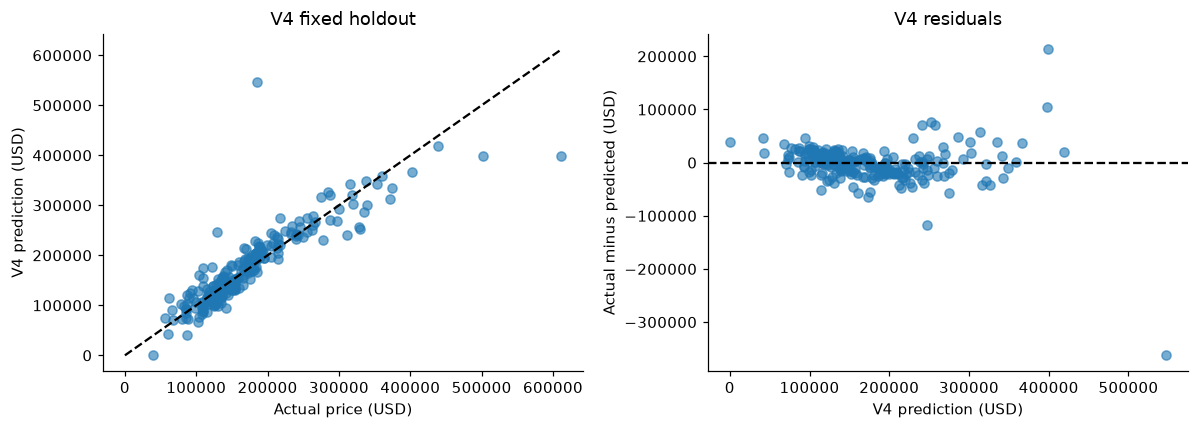

In [22]:
v4_holdout = pd.DataFrame({
    'Id': data.loc[y_valid.index, 'Id'],
    'Actual price': y_valid,
    'V1 prediction': v4_holdout_predictions['V1 linear'],
    'V4 prediction': v4_holdout_predictions[v4_name]
})
v4_holdout['V4 residual'] = v4_holdout['Actual price'] - v4_holdout['V4 prediction']
v4_holdout['Absolute error'] = v4_holdout['V4 residual'].abs()
display(v4_holdout.sort_values('Absolute error', ascending=False).head(5))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(v4_holdout['Actual price'], v4_holdout['V4 prediction'], alpha=0.6)
price_limits = [min(y_valid.min(), v4_holdout['V4 prediction'].min()),
                max(y_valid.max(), v4_holdout['V4 prediction'].max())]
axes[0].plot(price_limits, price_limits, '--', color='black')
axes[0].set(xlabel='Actual price (USD)', ylabel='V4 prediction (USD)', title='V4 fixed holdout')
axes[1].scatter(v4_holdout['V4 prediction'], v4_holdout['V4 residual'], alpha=0.6)
axes[1].axhline(0, linestyle='--', color='black')
axes[1].set(xlabel='V4 prediction (USD)', ylabel='Actual minus predicted (USD)', title='V4 residuals')
fig.tight_layout()
plt.show()


In [23]:
v4_model = clone(v4_candidates[v4_name])
v4_model.fit(prepare_features(X), y)
v4_predictions = np.maximum(
    v4_model.predict(prepare_features(test.drop(columns='Id'))), 0)
v4_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v4_predictions})
assert len(v4_submission) == 260
assert v4_submission['Id'].equals(sample['Id']) and v4_submission['Id'].is_unique
assert np.isfinite(v4_predictions).all() and (v4_predictions >= 0).all()
v4_submission.to_csv('ames_submission_v4.csv', index=False)
print('Saved ames_submission_v4.csv:', v4_submission.shape)
print('Prediction range:', v4_predictions.min(), 'to', v4_predictions.max())
display(v4_submission.head())


Saved ames_submission_v4.csv: (260, 2)
Prediction range: 50819.298779548844 to 624944.4381527499


,Id,SalePrice
0,0,"97,408.40"
1,1,"202,394.63"
2,2,"135,691.52"
3,3,"231,580.36"
4,4,"133,786.90"


## 13. V5: adjust Ridge alpha

V5 kept V4's features and changed Ridge alpha from 10 to 30. On the same five folds, the means were close: **31,843.01** for V4 and **31,851.92** for V5. The fixed holdout improved from **36,849.32** to **36,575.36**. Kaggle gave V5 **46,522.63795 public** and **29,054.06949 private**. The public score improved slightly, so we tried a blend next.

In [24]:
v5_model = Pipeline([
    ('prepare', clone(make_housing_model(numeric_features).named_steps['prepare'])),
    ('scale', StandardScaler(with_mean=False)),
    ('model', Ridge(alpha=30))
])
v5_model.fit(prepare_features(X), y)
v5_predictions = np.maximum(
    v5_model.predict(prepare_features(test.drop(columns='Id'))), 0)
v5_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v5_predictions})
assert len(v5_submission) == 260
assert v5_submission['Id'].equals(sample['Id']) and v5_submission['Id'].is_unique
assert np.isfinite(v5_predictions).all() and (v5_predictions >= 0).all()
v5_submission.to_csv('ames_submission_v5.csv', index=False)
print('Saved ames_submission_v5.csv:', v5_submission.shape)
display(v5_submission.head())

Saved ames_submission_v5.csv: (260, 2)


,Id,SalePrice
0,0,"97,860.10"
1,1,"201,966.62"
2,2,"136,746.72"
3,3,"231,819.48"
4,4,"133,616.63"


## 14. V1–V5 development log

| Version | What we changed | Local check | Public RMSE | Private RMSE | Next step |
|---|---|---|---:|---:|---|
| V1 | Original-year linear model; negative predictions set to zero | Saved 15-fold mean 32,132.82 | — | — | Starting point |
| V2 | Added area, condition, and sale-category features | 15-fold mean 31,604.68; holdout worsened | 48,933.65229 | 27,830.63078 | Went back to V1 features |
| V3 | Tried log-price Ridge, alpha=100 | 15-fold mean 29,353.15; holdout worsened | 93,548.61488 | 27,690.63477 | Returned to original prices |
| V4 | Used original-price Ridge, alpha=10 | 15-fold mean 32,036.76; holdout 36,849.32 | 46,902.58043 | 28,962.85640 | Adjusted alpha |
| V5 | Changed Ridge alpha to 30 | One 5-fold mean 31,851.92; holdout 36,575.36 | 46,522.63795 | 29,054.06949 | Tried a blend |

V1's earlier reported score was **47,747.14610**, but we do not have its public/private column label. Local and Kaggle checks use different houses, so they do not always rank the versions the same way.

## 15. V6: blend Ridge and random forest

We averaged V5 Ridge predictions with a random forest using V2's features. We also checked a few fixed blend weights and a gradient-boosting alternative. Each model's preprocessing was fitted inside the training folds. We chose the equal-weight Ridge and forest blend using the same local checks. V6 was not submitted to Kaggle.

In [25]:
v6_ridge = clone(v5_model)
v6_rf = Pipeline([
    ('prepare', clone(v4_extra_prepare)),
    ('model', RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=2))
])
v6_gb = Pipeline([
    ('prepare', clone(v4_extra_prepare)),
    ('model', GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=3,
        min_samples_leaf=10, random_state=42))
])
v6_prototypes = {'V5 Ridge': v6_ridge, 'Random forest': v6_rf,
                 'Gradient boosting': v6_gb}

def v6_predictions(fit_idx, score_idx):
    X_fit = prepare_features(X.iloc[fit_idx])
    X_score = prepare_features(X.iloc[score_idx])
    y_fit = y.iloc[fit_idx]
    predictions = {}
    for name, prototype in v6_prototypes.items():
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Found unknown categories')
            model = clone(prototype).fit(X_fit, y_fit)
            predictions[name] = np.maximum(model.predict(X_score), 0)
    return y.iloc[score_idx].to_numpy(), predictions

v6_rows = []
for repeat, seed in enumerate([42, 2026, 123], start=1):
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), start=1):
        actual, p = v6_predictions(fit_idx, score_idx)
        candidates = p.copy()
        for weight in [0.15, 0.25, 0.35, 0.50]:
            candidates[f'Ridge + RF {weight:.0%}'] = (
                (1 - weight) * p['V5 Ridge'] + weight * p['Random forest'])
            candidates[f'Ridge + GB {weight:.0%}'] = (
                (1 - weight) * p['V5 Ridge'] + weight * p['Gradient boosting'])
        for name, pred in candidates.items():
            v6_rows.append({'Repeat': repeat, 'Fold': fold, 'Model': name,
                            'RMSE': rmse(actual, pred)})
v6_details = pd.DataFrame(v6_rows)
v6_summary = v6_details.groupby('Model')['RMSE'].agg(['mean', 'std', 'max'])
v6_summary = v6_summary.sort_values('mean')
paired = v6_details.pivot(index=['Repeat', 'Fold'], columns='Model', values='RMSE')
v6_summary['Folds better than V5'] = [
    int((paired[name] < paired['V5 Ridge']).sum()) for name in v6_summary.index]
display(v6_summary)

holdout_actual, holdout_p = v6_predictions(
    X_train.index.to_numpy(), X_valid.index.to_numpy())
holdout_candidates = holdout_p.copy()
for weight in [0.15, 0.25, 0.35, 0.50]:
    holdout_candidates[f'Ridge + RF {weight:.0%}'] = (
        (1 - weight) * holdout_p['V5 Ridge'] + weight * holdout_p['Random forest'])
    holdout_candidates[f'Ridge + GB {weight:.0%}'] = (
        (1 - weight) * holdout_p['V5 Ridge'] + weight * holdout_p['Gradient boosting'])
holdout_table = pd.DataFrame([
    {'Model': name, 'Fixed-holdout RMSE': rmse(holdout_actual, pred)}
    for name, pred in holdout_candidates.items()
]).sort_values('Fixed-holdout RMSE')
display(holdout_table)


,mean,std,max,Folds better than V5
Model,,,,
Ridge + GB 50%,"29,252.47","5,598.65","37,142.33",14
Ridge + RF 50%,"29,323.55","5,326.99","36,123.66",15
Ridge + GB 35%,"29,720.19","5,392.07","36,767.05",14
Ridge + RF 35%,"29,780.13","5,219.43","36,287.53",15
Gradient boosting,"30,186.16","6,176.91","40,323.88",13
Random forest,"30,208.00","5,543.98","38,049.26",13
Ridge + GB 25%,"30,214.10","5,257.35","36,890.38",15
Ridge + RF 25%,"30,261.16","5,143.98","36,779.72",15
Ridge + GB 15%,"30,844.95","5,130.78","37,344.33",15


,Model,Fixed-holdout RMSE
7,Ridge + RF 35%,"35,959.05"
5,Ridge + RF 25%,"36,012.73"
9,Ridge + RF 50%,"36,064.11"
3,Ridge + RF 15%,"36,165.00"
4,Ridge + GB 15%,"36,452.78"
6,Ridge + GB 25%,"36,511.25"
0,V5 Ridge,"36,575.36"
8,Ridge + GB 35%,"36,681.38"
10,Ridge + GB 50%,"37,142.33"
1,Random forest,"37,969.17"


### V6 result

The equal-weight Ridge and forest blend had mean RMSE about **29,324** on 15 folds, compared with **32,029** for V5 Ridge, and was better in all 15 paired folds. The reused holdout was about **36,064** versus **36,575**. The gradient-boosting blend had a slightly lower fold mean but a worse holdout than V5, so we kept the Ridge and forest version for the next experiment. These are local development scores.

In [26]:
# Refit both components on all 1,200 labeled houses; test labels are not used.
v6_ridge_final = clone(v6_ridge).fit(prepare_features(X), y)
v6_rf_final = clone(v6_rf).fit(prepare_features(X), y)
test_features = prepare_features(test.drop(columns='Id'))
ridge_test = np.maximum(v6_ridge_final.predict(test_features), 0)
forest_test = np.maximum(v6_rf_final.predict(test_features), 0)
v6_test_predictions = 0.5 * ridge_test + 0.5 * forest_test
v6_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v6_test_predictions})
assert v6_submission.columns.tolist() == ['Id', 'SalePrice']
assert len(v6_submission) == 260 and v6_submission['Id'].equals(sample['Id'])
assert np.isfinite(v6_submission['SalePrice']).all()
assert (v6_submission['SalePrice'] >= 0).all()
v6_submission.to_csv('ames_submission_v6.csv', index=False)
print('Saved ames_submission_v6.csv:', v6_submission.shape)
print('Prediction range:', round(v6_submission.SalePrice.min(), 2),
      'to', round(v6_submission.SalePrice.max(), 2))
display(v6_submission.head())


Saved ames_submission_v6.csv: (260, 2)
Prediction range: 63218.23 to 541991.85


,Id,SalePrice
0,0,"104,775.94"
1,1,"206,830.71"
2,2,"130,786.61"
3,3,"224,789.11"
4,4,"139,446.82"


### V6 status

| Version | 15-fold mean RMSE | Reused holdout RMSE | Public RMSE | Private RMSE |
|---|---:|---:|---:|---:|
| V5 Ridge | 32,029 | 36,575 | 46,522.63795 | 29,054.06949 |
| V6 blend | 29,324 | 36,064 | — | — |

The code in this section creates `ames_submission_v6.csv`. We did not upload V6, so it has no Kaggle score.

## 16. V7: try Huber boosting

A few houses had very large errors, so we tried `GradientBoostingRegressor(loss='huber')` as a third component. We compared it with V6 and several preset blend weights. We used the same 15 folds, five additional folds, and two holdouts. All of these labeled houses had already influenced our choices, so these scores are for comparing models rather than an untouched final test. We did not load `solns.csv`.

In [27]:
from sklearn.ensemble import ExtraTreesRegressor

v7_huber = Pipeline([
    ('prepare', clone(v4_extra_prepare)),
    ('model', GradientBoostingRegressor(
        loss='huber', n_estimators=250, learning_rate=0.05,
        max_depth=3, min_samples_leaf=10, random_state=42))
])
v7_et = Pipeline([
    ('prepare', clone(v4_extra_prepare)),
    ('model', ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=2))
])
v7_prototypes = {
    'Ridge': v6_ridge,
    'RF': v6_rf,
    'Extra trees': v7_et,
    'GB squared error': v6_gb,
    'GB Huber': v7_huber,
}

def v7_score_split(fit_idx, score_idx, label):
    X_fit = prepare_features(X.iloc[fit_idx])
    X_score = prepare_features(X.iloc[score_idx])
    y_fit = y.iloc[fit_idx]
    actual = y.iloc[score_idx].to_numpy()
    p = {}
    for name, prototype in v7_prototypes.items():
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Found unknown categories')
            model = clone(prototype).fit(X_fit, y_fit)
            p[name] = np.maximum(model.predict(X_score), 0)
    candidates = p.copy()
    candidates['V6: 50% Ridge + 50% RF'] = 0.5*p['Ridge'] + 0.5*p['RF']
    candidates['50% Ridge + 50% Extra trees'] = 0.5*p['Ridge'] + 0.5*p['Extra trees']
    candidates['40% Ridge + 30% RF + 30% Extra trees'] = (
        0.4*p['Ridge'] + 0.3*p['RF'] + 0.3*p['Extra trees'])
    candidates['40% Ridge + 30% RF + 30% GB squared'] = (
        0.4*p['Ridge'] + 0.3*p['RF'] + 0.3*p['GB squared error'])
    candidates['V7: 40% Ridge + 30% RF + 30% GB Huber'] = (
        0.4*p['Ridge'] + 0.3*p['RF'] + 0.3*p['GB Huber'])
    candidates['30% Ridge + 35% RF + 35% GB squared'] = (
        0.3*p['Ridge'] + 0.35*p['RF'] + 0.35*p['GB squared error'])
    candidates['20% Ridge + 40% RF + 40% GB squared'] = (
        0.2*p['Ridge'] + 0.4*p['RF'] + 0.4*p['GB squared error'])
    candidates['50% Ridge + 25% RF + 25% GB squared'] = (
        0.5*p['Ridge'] + 0.25*p['RF'] + 0.25*p['GB squared error'])
    return [{'Split': label, 'Model': name, 'RMSE': rmse(actual, pred)}
            for name, pred in candidates.items()]

v7_rows = []
for seed in [42, 2026, 123, 101]:
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), 1):
        v7_rows += v7_score_split(fit_idx, score_idx, f'cv{seed}_{fold}')
v7_rows += v7_score_split(np.arange(960), np.arange(960, 1200), 'last240')
v7_rows += v7_score_split(X_train.index.to_numpy(), X_valid.index.to_numpy(),
                          'oldholdout')
v7_details = pd.DataFrame(v7_rows)
v7_pivot = v7_details.pivot(index='Split', columns='Model', values='RMSE')
v7_summary = pd.DataFrame({
    'Original 15-fold mean': v7_pivot.loc[v7_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))].mean(),
    'New 5-fold mean': v7_pivot.loc[v7_pivot.index.str.startswith('cv101_')].mean(),
    'Last-240 RMSE': v7_pivot.loc['last240'],
    'Original holdout RMSE': v7_pivot.loc['oldholdout'],
}).sort_values('Original 15-fold mean')
display(v7_summary)
v7_name = 'V7: 40% Ridge + 30% RF + 30% GB Huber'
v6_name = 'V6: 50% Ridge + 50% RF'
for label, subset in [
    ('Original 15 folds', v7_pivot.loc[v7_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))]),
    ('New 5 folds', v7_pivot.loc[v7_pivot.index.str.startswith('cv101_')])]:
    print(label, 'V7 beats V6 in', int((subset[v7_name] < subset[v6_name]).sum()),
          'of', len(subset), 'folds')


,Original 15-fold mean,New 5-fold mean,Last-240 RMSE,Original holdout RMSE
Model,,,,
V7: 40% Ridge + 30% RF + 30% GB Huber,"28,804.13","28,267.22","31,400.69","35,688.80"
40% Ridge + 30% RF + 30% Extra trees,"28,850.25","28,789.06","31,793.24","35,840.19"
30% Ridge + 35% RF + 35% GB squared,"28,865.42","28,066.40","30,038.25","37,091.74"
40% Ridge + 30% RF + 30% GB squared,"28,922.46","28,205.53","30,461.10","36,738.22"
20% Ridge + 40% RF + 40% GB squared,"28,949.61","28,076.51","29,712.85","37,533.80"
50% Ridge + 50% Extra trees,"29,060.98","29,191.77","32,267.67","35,566.66"
50% Ridge + 25% RF + 25% GB squared,"29,119.40","28,492.11","30,977.43","36,475.81"
GB Huber,"29,321.23","28,245.23","30,500.87","36,469.90"
V6: 50% Ridge + 50% RF,"29,323.55","29,077.86","32,185.53","36,064.11"


Original 15 folds V7 beats V6 in 12 of 15 folds
New 5 folds V7 beats V6 in 5 of 5 folds


### V7 choice

We chose 40% Ridge, 30% random forest, and 30% Huber boosting. Mean RMSE fell from **29,324** for V6 to **28,804** on the original 15 folds, with V7 better in 12 folds. On five additional folds, it was **28,267** versus **29,078**. The last-240 check improved from **32,186** to **31,401**, and the original holdout from **36,064** to **35,689**. We kept all houses, including the difficult ones.

In [28]:
v7_ridge_final = clone(v6_ridge).fit(prepare_features(X), y)
v7_rf_final = clone(v6_rf).fit(prepare_features(X), y)
v7_huber_final = clone(v7_huber).fit(prepare_features(X), y)
v7_test_features = prepare_features(test.drop(columns='Id'))
v7_predictions = (
    0.4 * np.maximum(v7_ridge_final.predict(v7_test_features), 0) +
    0.3 * np.maximum(v7_rf_final.predict(v7_test_features), 0) +
    0.3 * np.maximum(v7_huber_final.predict(v7_test_features), 0)
)
v7_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v7_predictions})
assert v7_submission.columns.tolist() == ['Id', 'SalePrice']
assert len(v7_submission) == 260 and v7_submission['Id'].equals(sample['Id'])
assert np.isfinite(v7_submission['SalePrice']).all()
assert (v7_submission['SalePrice'] >= 0).all()
v7_submission.to_csv('ames_submission_v7.csv', index=False)
print('Saved ames_submission_v7.csv:', v7_submission.shape)
print('Prediction range:', round(v7_submission.SalePrice.min(), 2),
      'to', round(v7_submission.SalePrice.max(), 2))
display(v7_submission.head())


Saved ames_submission_v7.csv: (260, 2)
Prediction range: 62820.74 to 541294.22


,Id,SalePrice
0,0,"105,878.54"
1,1,"205,240.05"
2,2,"131,817.02"
3,3,"223,908.54"
4,4,"139,958.57"


### V7 Kaggle result

We uploaded `ames_submission_v7.csv`. It scored **38,539.35879 public** and **25,786.57620 private**. Compared with V5, those scores were lower by **7,983.27916** and **3,267.49329**, respectively.

## 17. V8: add finished-space features

We kept V7's three-model blend and added basement finished area, basement unfinished area, masonry veneer area, open porch area, and wood deck area to the two tree models. Ridge stayed the same. We also tried a larger amenity set. Capping large areas at the 99th percentile helped one holdout but worsened both fold groups and the last-240 check, so we dropped that idea. No houses were removed or relabeled.

In [29]:
v8_saved_categories = category_features.copy()
category_features = v8_saved_categories + ['SaleCondition']
v8_finish_numeric = v2_numeric + [
    'BsmtFinSF1', 'BsmtUnfSF', 'MasVnrArea', 'OpenPorchSF', 'WoodDeckSF']
v8_finish_prepare = clone(make_housing_model(v8_finish_numeric).named_steps['prepare'])
v8_amenity_numeric = v8_finish_numeric + [
    'LotFrontage', 'TotRmsAbvGrd', 'HalfBath']
category_features = v8_saved_categories + ['SaleCondition', 'Foundation', 'CentralAir']
v8_amenity_prepare = clone(make_housing_model(v8_amenity_numeric).named_steps['prepare'])
category_features = v8_saved_categories

def v8_tree_models(preprocessor):
    forest = Pipeline([
        ('prepare', clone(preprocessor)),
        ('model', RandomForestRegressor(
            n_estimators=250, min_samples_leaf=2, max_features=0.8,
            random_state=42, n_jobs=2))])
    huber = Pipeline([
        ('prepare', clone(preprocessor)),
        ('model', GradientBoostingRegressor(
            loss='huber', n_estimators=250, learning_rate=0.05,
            max_depth=3, min_samples_leaf=10, random_state=42))])
    return forest, huber

v8_finish_rf, v8_finish_huber = v8_tree_models(v8_finish_prepare)
v8_amenity_rf, v8_amenity_huber = v8_tree_models(v8_amenity_prepare)
v8_prototypes = {
    'Ridge': v6_ridge,
    'Current RF': v6_rf, 'Current Huber': v7_huber,
    'Finished-space RF': v8_finish_rf, 'Finished-space Huber': v8_finish_huber,
    'Amenity RF': v8_amenity_rf, 'Amenity Huber': v8_amenity_huber,
}

def v8_score_split(fit_idx, score_idx, label):
    X_fit = prepare_features(X.iloc[fit_idx])
    X_score = prepare_features(X.iloc[score_idx])
    y_fit = y.iloc[fit_idx]
    actual = y.iloc[score_idx].to_numpy()
    preds = {}
    for name, prototype in v8_prototypes.items():
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Found unknown categories')
            model = clone(prototype).fit(X_fit, y_fit)
            preds[name] = np.maximum(model.predict(X_score), 0)
    candidates = {}
    for label_name, forest_name, huber_name in [
        ('V7: current features', 'Current RF', 'Current Huber'),
        ('V8: finished-space features', 'Finished-space RF', 'Finished-space Huber'),
        ('Larger amenity set', 'Amenity RF', 'Amenity Huber')]:
        candidates[label_name] = (
            0.4 * preds['Ridge'] +
            0.3 * preds[forest_name] +
            0.3 * preds[huber_name])
    return [{'Split': label, 'Model': name, 'RMSE': rmse(actual, pred)}
            for name, pred in candidates.items()]

v8_rows = []
for seed in [42, 2026, 123, 101]:
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), 1):
        v8_rows += v8_score_split(fit_idx, score_idx, f'cv{seed}_{fold}')
v8_rows += v8_score_split(np.arange(960), np.arange(960, 1200), 'last240')
v8_rows += v8_score_split(X_train.index.to_numpy(), X_valid.index.to_numpy(),
                          'oldholdout')
v8_details = pd.DataFrame(v8_rows)
v8_pivot = v8_details.pivot(index='Split', columns='Model', values='RMSE')
v8_summary = pd.DataFrame({
    'Original 15-fold mean': v8_pivot.loc[v8_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))].mean(),
    'New 5-fold mean': v8_pivot.loc[v8_pivot.index.str.startswith('cv101_')].mean(),
    'Last-240 RMSE': v8_pivot.loc['last240'],
    'Original holdout RMSE': v8_pivot.loc['oldholdout'],
}).sort_values('Original 15-fold mean')
display(v8_summary)
for name in ['V8: finished-space features', 'Larger amenity set']:
    for label, subset in [
        ('Original 15 folds', v8_pivot.loc[v8_pivot.index.str.startswith(
            ('cv42_', 'cv2026_', 'cv123_'))]),
        ('New 5 folds', v8_pivot.loc[v8_pivot.index.str.startswith('cv101_')])]:
        print(name, label, 'better than V7:',
              int((subset[name] < subset['V7: current features']).sum()),
              'of', len(subset))


,Original 15-fold mean,New 5-fold mean,Last-240 RMSE,Original holdout RMSE
Model,,,,
V8: finished-space features,"28,319.19","27,820.28","30,637.70","34,916.89"
Larger amenity set,"28,357.39","27,717.78","30,727.15","35,064.72"
V7: current features,"28,804.13","28,267.22","31,400.69","35,688.80"


V8: finished-space features Original 15 folds better than V7: 13 of 15
V8: finished-space features New 5 folds better than V7: 4 of 5
Larger amenity set Original 15 folds better than V7: 11 of 15
Larger amenity set New 5 folds better than V7: 4 of 5


### V8 choice

The five added features gave lower RMSE than V7 on all four local summaries: **28,319 versus 28,804** on the original 15 folds, **27,820 versus 28,267** on five later folds, **30,638 versus 31,401** on the last-240 check, and **34,917 versus 35,689** on the original holdout. The larger amenity set only improved the later five-fold mean, so we chose the smaller set.

In [30]:
v8_ridge_final = clone(v6_ridge).fit(prepare_features(X), y)
v8_rf_final = clone(v8_finish_rf).fit(prepare_features(X), y)
v8_huber_final = clone(v8_finish_huber).fit(prepare_features(X), y)
v8_test_features = prepare_features(test.drop(columns='Id'))
v8_predictions = (
    0.4 * np.maximum(v8_ridge_final.predict(v8_test_features), 0) +
    0.3 * np.maximum(v8_rf_final.predict(v8_test_features), 0) +
    0.3 * np.maximum(v8_huber_final.predict(v8_test_features), 0)
)
v8_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v8_predictions})
assert v8_submission.columns.tolist() == ['Id', 'SalePrice']
assert len(v8_submission) == 260 and v8_submission['Id'].equals(sample['Id'])
assert np.isfinite(v8_submission['SalePrice']).all()
assert (v8_submission['SalePrice'] >= 0).all()
v8_submission.to_csv('ames_submission_v8.csv', index=False)
print('Saved ames_submission_v8.csv:', v8_submission.shape)
print('Prediction range:', round(v8_submission.SalePrice.min(), 2),
      'to', round(v8_submission.SalePrice.max(), 2))
display(v8_submission.head())


Saved ames_submission_v8.csv: (260, 2)
Prediction range: 63349.7 to 538372.93


,Id,SalePrice
0,0,"102,500.37"
1,1,"203,022.94"
2,2,"128,404.25"
3,3,"220,928.61"
4,4,"139,719.34"


### V8 Kaggle result

V8 scored **37,981.98779 public** and **24,559.78418 private**. Both were lower than V7: by **557.37100** public and **1,226.79202** private. We kept the added finished-space features.

## 18. V9: change blend weights

V8 improved both Kaggle columns, so we kept its features and three model types. We compared a short list of blend weights on the same 20 folds and two holdouts. Every fold refitted the preprocessing and models using only its training rows. We did not use Kaggle test labels or `solns.csv`.

In [31]:
v9_prototypes = {
    'Ridge': v6_ridge,
    'Random forest': v8_finish_rf,
    'Huber boosting': v8_finish_huber,
}
v9_weights = {
    'V8: 40/30/30': (0.40, 0.30, 0.30),
    '30/35/35': (0.30, 0.35, 0.35),
    'V9: 30/30/40': (0.30, 0.30, 0.40),
    '30/40/30': (0.30, 0.40, 0.30),
    '40/20/40': (0.40, 0.20, 0.40),
    '40/40/20': (0.40, 0.40, 0.20),
    '20/40/40': (0.20, 0.40, 0.40),
    '20/30/50': (0.20, 0.30, 0.50),
    '50/25/25': (0.50, 0.25, 0.25),
    '50/20/30': (0.50, 0.20, 0.30),
}

def v9_score_split(fit_idx, score_idx, label):
    X_fit = prepare_features(X.iloc[fit_idx])
    X_score = prepare_features(X.iloc[score_idx])
    y_fit = y.iloc[fit_idx]
    actual = y.iloc[score_idx].to_numpy()
    preds = {}
    for name, prototype in v9_prototypes.items():
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Found unknown categories')
            model = clone(prototype).fit(X_fit, y_fit)
            preds[name] = np.maximum(model.predict(X_score), 0)
    rows = []
    for name, (ridge_w, forest_w, huber_w) in v9_weights.items():
        blended = (ridge_w * preds['Ridge'] +
                   forest_w * preds['Random forest'] +
                   huber_w * preds['Huber boosting'])
        rows.append({'Split': label, 'Weights': name,
                     'RMSE': rmse(actual, blended)})
    return rows

v9_rows = []
for seed in [42, 2026, 123, 101]:
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), 1):
        v9_rows += v9_score_split(fit_idx, score_idx, f'cv{seed}_{fold}')
v9_rows += v9_score_split(np.arange(960), np.arange(960, 1200), 'last240')
v9_rows += v9_score_split(X_train.index.to_numpy(), X_valid.index.to_numpy(),
                          'oldholdout')
v9_details = pd.DataFrame(v9_rows)
v9_pivot = v9_details.pivot(index='Split', columns='Weights', values='RMSE')
v9_summary = pd.DataFrame({
    'Original 15-fold mean': v9_pivot.loc[v9_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))].mean(),
    'New 5-fold mean': v9_pivot.loc[v9_pivot.index.str.startswith('cv101_')].mean(),
    'Last-240 RMSE': v9_pivot.loc['last240'],
    'Original holdout RMSE': v9_pivot.loc['oldholdout'],
}).sort_values('Original 15-fold mean')
display(v9_summary)
for name in ['V9: 30/30/40', '20/30/50']:
    for label, subset in [
        ('Original 15 folds', v9_pivot.loc[v9_pivot.index.str.startswith(
            ('cv42_', 'cv2026_', 'cv123_'))]),
        ('New 5 folds', v9_pivot.loc[v9_pivot.index.str.startswith('cv101_')])]:
        print(name, label, 'beats V8 in',
              int((subset[name] < subset['V8: 40/30/30']).sum()),
              'of', len(subset), 'folds')


,Original 15-fold mean,New 5-fold mean,Last-240 RMSE,Original holdout RMSE
Weights,,,,
20/30/50,"28,084.76","27,427.76","29,945.32","34,971.29"
V9: 30/30/40,"28,126.47","27,545.34","30,233.73","34,892.63"
20/40/40,"28,136.76","27,557.46","30,045.52","35,103.75"
30/35/35,"28,155.89","27,612.82","30,286.76","34,963.46"
30/40/30,"28,197.57","27,694.13","30,350.59","35,044.07"
40/20/40,"28,278.45","27,708.98","30,547.72","34,786.08"
V8: 40/30/30,"28,319.19","27,820.28","30,637.70","34,916.89"
40/40/20,"28,408.62","27,986.65","30,770.40","35,086.89"
50/20/30,"28,600.09","28,119.29","31,047.05","34,894.78"


V9: 30/30/40 Original 15 folds beats V8 in 11 of 15 folds
V9: 30/30/40 New 5 folds beats V8 in 5 of 5 folds
20/30/50 Original 15 folds beats V8 in 10 of 15 folds
20/30/50 New 5 folds beats V8 in 5 of 5 folds


### V9 choice

We chose 30% Ridge, 30% forest, and 40% Huber boosting. The original 15-fold mean fell from **28,319** to **28,126**; the later five-fold mean fell from **27,820** to **27,545**. The last-240 check improved from **30,638** to **30,234**. The original holdout was nearly tied, **34,917** versus **34,893**. A 20/30/50 blend had a lower fold mean but made that holdout slightly worse, so we stayed with 30/30/40.

In [32]:
# Model types and features are identical to V8; refit each component on all labels.
v9_ridge_final = clone(v6_ridge).fit(prepare_features(X), y)
v9_rf_final = clone(v8_finish_rf).fit(prepare_features(X), y)
v9_huber_final = clone(v8_finish_huber).fit(prepare_features(X), y)
v9_test_features = prepare_features(test.drop(columns='Id'))
v9_predictions = (
    0.30 * np.maximum(v9_ridge_final.predict(v9_test_features), 0) +
    0.30 * np.maximum(v9_rf_final.predict(v9_test_features), 0) +
    0.40 * np.maximum(v9_huber_final.predict(v9_test_features), 0)
)
v9_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v9_predictions})
assert v9_submission.columns.tolist() == ['Id', 'SalePrice']
assert len(v9_submission) == 260 and v9_submission['Id'].equals(sample['Id'])
assert np.isfinite(v9_submission['SalePrice']).all()
assert (v9_submission['SalePrice'] >= 0).all()
v9_submission.to_csv('ames_submission_v9.csv', index=False)
print('Saved ames_submission_v9.csv:', v9_submission.shape)
print('Prediction range:', round(v9_submission.SalePrice.min(), 2),
      'to', round(v9_submission.SalePrice.max(), 2))
display(v9_submission.head())


Saved ames_submission_v9.csv: (260, 2)
Prediction range: 64072.06 to 527267.35


,Id,SalePrice
0,0,"102,935.50"
1,1,"202,713.87"
2,2,"127,304.67"
3,3,"219,000.82"
4,4,"140,648.33"


### V9 Kaggle result

V9 scored **36,923.54265 public** and **24,300.38740 private**, improvements of **1,058.44514** and **259.39678** over V8. The features stayed the same; only the blend weights changed.

## 19. V10: adjust Huber boosting

We kept V9's features, Ridge model, and forest. We compared Huber alpha values 0.80, 0.90, and 0.95, plus 350 instead of 250 boosting trees at alpha=0.90. We checked each at 30/30/40 and 20/30/50 weights on the same folds and holdouts. These checks had already been used in earlier decisions, so small differences need caution.

In [33]:
v10_huber_80 = clone(v8_finish_huber).set_params(model__alpha=0.80)
v10_huber_95 = clone(v8_finish_huber).set_params(model__alpha=0.95)
v10_huber_350 = clone(v8_finish_huber).set_params(model__n_estimators=350)
v10_prototypes = {
    'Ridge': v6_ridge,
    'Random forest': v8_finish_rf,
    'Huber90': v8_finish_huber,
    'Huber80': v10_huber_80,
    'Huber95': v10_huber_95,
    'Huber90_350': v10_huber_350,
}
v10_candidates = {}
for huber_name in ['Huber90', 'Huber80', 'Huber95', 'Huber90_350']:
    v10_candidates[f'{huber_name} 30/30/40'] = (huber_name, 0.30, 0.30, 0.40)
    v10_candidates[f'{huber_name} 20/30/50'] = (huber_name, 0.20, 0.30, 0.50)

def v10_score_split(fit_idx, score_idx, label):
    X_fit = prepare_features(X.iloc[fit_idx])
    X_score = prepare_features(X.iloc[score_idx])
    y_fit = y.iloc[fit_idx]
    actual = y.iloc[score_idx].to_numpy()
    p = {}
    for name, prototype in v10_prototypes.items():
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Found unknown categories')
            model = clone(prototype).fit(X_fit, y_fit)
            p[name] = np.maximum(model.predict(X_score), 0)
    rows = []
    for name, (huber_name, ridge_w, forest_w, huber_w) in v10_candidates.items():
        pred = (ridge_w * p['Ridge'] + forest_w * p['Random forest'] +
                huber_w * p[huber_name])
        rows.append({'Split': label, 'Candidate': name,
                     'RMSE': rmse(actual, pred)})
    return rows

v10_rows = []
for seed in [42, 2026, 123, 101]:
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), 1):
        v10_rows += v10_score_split(fit_idx, score_idx, f'cv{seed}_{fold}')
v10_rows += v10_score_split(np.arange(960), np.arange(960, 1200), 'last240')
v10_rows += v10_score_split(X_train.index.to_numpy(), X_valid.index.to_numpy(),
                            'oldholdout')
v10_details = pd.DataFrame(v10_rows)
v10_pivot = v10_details.pivot(index='Split', columns='Candidate', values='RMSE')
v10_summary = pd.DataFrame({
    'Original 15-fold mean': v10_pivot.loc[v10_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))].mean(),
    'New 5-fold mean': v10_pivot.loc[v10_pivot.index.str.startswith('cv101_')].mean(),
    'Last-240 RMSE': v10_pivot.loc['last240'],
    'Original holdout RMSE': v10_pivot.loc['oldholdout'],
}).sort_values('Original 15-fold mean')
display(v10_summary)
v10_name = 'Huber90_350 20/30/50'
v9_name = 'Huber90 30/30/40'
for label, subset in [
    ('Original 15 folds', v10_pivot.loc[v10_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))]),
    ('New 5 folds', v10_pivot.loc[v10_pivot.index.str.startswith('cv101_')])]:
    print('V10 beats V9 in', int((subset[v10_name] < subset[v9_name]).sum()),
          'of', len(subset), label)


,Original 15-fold mean,New 5-fold mean,Last-240 RMSE,Original holdout RMSE
Candidate,,,,
Huber90_350 20/30/50,"27,943.31","27,272.69","29,604.97","35,028.82"
Huber90_350 30/30/40,"28,007.28","27,413.83","29,958.82","34,930.63"
Huber80 20/30/50,"28,062.88","27,523.97","29,955.36","34,778.49"
Huber95 20/30/50,"28,074.91","27,371.36","29,706.34","35,183.15"
Huber90 20/30/50,"28,084.76","27,427.76","29,945.32","34,971.29"
Huber95 30/30/40,"28,113.04","27,490.43","30,044.95","35,040.42"
Huber80 30/30/40,"28,113.68","27,619.68","30,229.30","34,728.51"
Huber90 30/30/40,"28,126.47","27,545.34","30,233.73","34,892.63"


V10 beats V9 in 11 of 15 Original 15 folds
V10 beats V9 in 5 of 5 New 5 folds


### V10 choice

We chose 20% Ridge, 30% forest, and 50% Huber boosting with 350 trees and alpha=0.90. The original 15-fold mean improved from **28,126** to **27,943**, and the later five-fold mean from **27,545** to **27,273**. The last-240 check improved from **30,234** to **29,605**. The original holdout became slightly worse, **35,029** versus **34,893**. We kept that mixed result in the record.

In [34]:
v10_ridge_final = clone(v6_ridge).fit(prepare_features(X), y)
v10_rf_final = clone(v8_finish_rf).fit(prepare_features(X), y)
v10_huber_final = clone(v10_huber_350).fit(prepare_features(X), y)
v10_test_features = prepare_features(test.drop(columns='Id'))
v10_predictions = (
    0.20 * np.maximum(v10_ridge_final.predict(v10_test_features), 0) +
    0.30 * np.maximum(v10_rf_final.predict(v10_test_features), 0) +
    0.50 * np.maximum(v10_huber_final.predict(v10_test_features), 0)
)
v10_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v10_predictions})
assert v10_submission.columns.tolist() == ['Id', 'SalePrice']
assert len(v10_submission) == 260 and v10_submission['Id'].equals(sample['Id'])
assert np.isfinite(v10_submission['SalePrice']).all()
assert (v10_submission['SalePrice'] >= 0).all()
v10_submission.to_csv('ames_submission_v10.csv', index=False)
print('Saved ames_submission_v10.csv:', v10_submission.shape)
print('Prediction range:', round(v10_submission.SalePrice.min(), 2),
      'to', round(v10_submission.SalePrice.max(), 2))
display(v10_submission.head())


Saved ames_submission_v10.csv: (260, 2)
Prediction range: 64454.88 to 519067.25


,Id,SalePrice
0,0,"102,936.69"
1,1,"202,749.38"
2,2,"127,586.26"
3,3,"216,917.99"
4,4,"141,924.31"


### V10 Kaggle result

V10 scored **36,051.69991 public** and **24,149.83432 private**. Both were lower than V9, by **871.84274** and **150.55308**. We then tested a different tree component for V11.

## 20. V11: compare the tree component

We kept V10's features, weights, Ridge model, and Huber model. For the 30% tree component, we compared several forest settings with `ExtraTreesRegressor`. Before that, we tried more boosting trees and more Huber weight, but the holdout worsened. Adding total finished area, total bathrooms, and outdoor area also gave inconsistent results. The comparison below uses the same 20 folds and two holdouts. No rows were removed.

In [35]:
from sklearn.ensemble import ExtraTreesRegressor

v11_tree_prototypes = {
    'V10 random forest': v8_finish_rf,
    'RF leaf=1': Pipeline([
        ('prepare', clone(v8_finish_prepare)),
        ('model', RandomForestRegressor(
            n_estimators=250, min_samples_leaf=1, max_features=0.8,
            random_state=42, n_jobs=2))]),
    'RF leaf=3': Pipeline([
        ('prepare', clone(v8_finish_prepare)),
        ('model', RandomForestRegressor(
            n_estimators=250, min_samples_leaf=3, max_features=0.8,
            random_state=42, n_jobs=2))]),
    'RF max_features=1.0': Pipeline([
        ('prepare', clone(v8_finish_prepare)),
        ('model', RandomForestRegressor(
            n_estimators=250, min_samples_leaf=2, max_features=1.0,
            random_state=42, n_jobs=2))]),
    'RF max_features=0.6': Pipeline([
        ('prepare', clone(v8_finish_prepare)),
        ('model', RandomForestRegressor(
            n_estimators=250, min_samples_leaf=2, max_features=0.6,
            random_state=42, n_jobs=2))]),
    'V11 Extra Trees': Pipeline([
        ('prepare', clone(v8_finish_prepare)),
        ('model', ExtraTreesRegressor(
            n_estimators=250, min_samples_leaf=2, max_features=0.8,
            random_state=42, n_jobs=2))]),
}
v11_components = {'Ridge': v6_ridge, 'Huber': v10_huber_350}
v11_components.update(v11_tree_prototypes)

def v11_score_split(fit_idx, score_idx, label):
    X_fit = prepare_features(X.iloc[fit_idx])
    X_score = prepare_features(X.iloc[score_idx])
    y_fit = y.iloc[fit_idx]
    actual = y.iloc[score_idx].to_numpy()
    preds = {}
    for name, prototype in v11_components.items():
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Found unknown categories')
            model = clone(prototype).fit(X_fit, y_fit)
            preds[name] = np.maximum(model.predict(X_score), 0)
    rows = []
    for name in v11_tree_prototypes:
        combined = (0.20 * preds['Ridge'] + 0.30 * preds[name] +
                    0.50 * preds['Huber'])
        rows.append({'Split': label, 'Tree component': name,
                     'RMSE': rmse(actual, combined)})
    return rows

v11_rows = []
for seed in [42, 2026, 123, 101]:
    for fold, (fit_idx, score_idx) in enumerate(
            KFold(n_splits=5, shuffle=True, random_state=seed).split(X), 1):
        v11_rows += v11_score_split(fit_idx, score_idx, f'cv{seed}_{fold}')
v11_rows += v11_score_split(np.arange(960), np.arange(960, 1200), 'last240')
v11_rows += v11_score_split(X_train.index.to_numpy(), X_valid.index.to_numpy(),
                            'oldholdout')
v11_details = pd.DataFrame(v11_rows)
v11_pivot = v11_details.pivot(index='Split', columns='Tree component', values='RMSE')
v11_summary = pd.DataFrame({
    'Original 15-fold mean': v11_pivot.loc[v11_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))].mean(),
    'New 5-fold mean': v11_pivot.loc[v11_pivot.index.str.startswith('cv101_')].mean(),
    'Last-240 RMSE': v11_pivot.loc['last240'],
    'Original holdout RMSE': v11_pivot.loc['oldholdout'],
}).sort_values('Original 15-fold mean')
display(v11_summary)
for label, subset in [
    ('Original 15 folds', v11_pivot.loc[v11_pivot.index.str.startswith(
        ('cv42_', 'cv2026_', 'cv123_'))]),
    ('New 5 folds', v11_pivot.loc[v11_pivot.index.str.startswith('cv101_')])]:
    print('Extra Trees beats V10 in',
          int((subset['V11 Extra Trees'] < subset['V10 random forest']).sum()),
          'of', len(subset), label)


,Original 15-fold mean,New 5-fold mean,Last-240 RMSE,Original holdout RMSE
Tree component,,,,
V11 Extra Trees,"27,681.49","27,115.00","29,546.71","34,668.73"
RF leaf=1,"27,831.12","27,061.56","28,714.92","35,202.88"
RF max_features=1.0,"27,937.16","27,336.52","29,570.57","34,934.26"
V10 random forest,"27,943.31","27,272.69","29,604.97","35,028.82"
RF max_features=0.6,"27,973.42","27,179.52","29,655.76","35,113.58"
RF leaf=3,"28,113.28","27,361.69","30,343.32","34,966.79"


Extra Trees beats V10 in 10 of 15 Original 15 folds
Extra Trees beats V10 in 3 of 5 New 5 folds


### V11 choice

We chose 20% Ridge, 30% Extra Trees, and 50% Huber boosting. Compared with V10, the original 15-fold mean improved from **27,943** to **27,681**, and the later five-fold mean from **27,273** to **27,115**. The last-240 check improved from **29,605** to **29,547**, and the original holdout from **35,029** to **34,669**. A leaf-1 forest helped some checks more but worsened the original holdout, so we kept Extra Trees.

In [36]:
v11_ridge_final = clone(v6_ridge).fit(prepare_features(X), y)
v11_tree_final = clone(v11_tree_prototypes['V11 Extra Trees']).fit(
    prepare_features(X), y)
v11_huber_final = clone(v10_huber_350).fit(prepare_features(X), y)
v11_test_features = prepare_features(test.drop(columns='Id'))
v11_predictions = (
    0.20 * np.maximum(v11_ridge_final.predict(v11_test_features), 0) +
    0.30 * np.maximum(v11_tree_final.predict(v11_test_features), 0) +
    0.50 * np.maximum(v11_huber_final.predict(v11_test_features), 0)
)
v11_submission = pd.DataFrame({'Id': sample['Id'], 'SalePrice': v11_predictions})
assert v11_submission.columns.tolist() == ['Id', 'SalePrice']
assert len(v11_submission) == 260 and v11_submission['Id'].equals(sample['Id'])
assert np.isfinite(v11_submission['SalePrice']).all()
assert (v11_submission['SalePrice'] >= 0).all()
v11_submission.to_csv('ames_submission_v11.csv', index=False)
print('Saved ames_submission_v11.csv:', v11_submission.shape)
print('Prediction range:', round(v11_submission.SalePrice.min(), 2),
      'to', round(v11_submission.SalePrice.max(), 2))
display(v11_submission.head())


Saved ames_submission_v11.csv: (260, 2)
Prediction range: 63868.73 to 492632.68


,Id,SalePrice
0,0,"103,049.45"
1,1,"200,725.52"
2,2,"131,408.33"
3,3,"216,594.81"
4,4,"142,137.96"


### V11 Kaggle result

The last code cell creates `ames_submission_v11.csv`. We submitted it and received **33,765.45286 public RMSE** and **23,767.77978 private RMSE**. These are lower than V10 by **2,286.24705** public and **382.05454** private. V11 has the lowest scores of our recorded submissions.